In [1]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Generate a small synthetic binary classification dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert labels to column vectors
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

# Initialize neural network parameters
np.random.seed(42)

input_size = 2
hidden_size = 8
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)
print("Initial parameters created successfully.")


Training data: (800, 2)
Testing data: (200, 2)
W1 shape: (2, 8)
W2 shape: (8, 1)
Initial parameters created successfully.


In [2]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Generate a small synthetic binary classification dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Convert labels to column vectors
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

# Initialize neural network parameters
np.random.seed(42)

input_size = 2
hidden_size = 8
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)
print("Initial parameters created successfully.")


Training data: (800, 2)
Testing data: (200, 2)
W1 shape: (2, 8)
W2 shape: (8, 1)
Initial parameters created successfully.


In [3]:

def sigmoid(z):
    # Clip values to prevent numerical overflow
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def forward_pass(X, W1, b1, W2, b2):
    # Hidden layer
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)

    # Output layer
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    # Save intermediate values for backpropagation
    cache = {
        "X": X,
        "z1": z1,
        "a1": a1,
        "z2": z2,
        "a2": a2
    }

    return a2, cache


def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-7
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred)
        + (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Test the forward pass
predictions, cache = forward_pass(
    X_train, W1, b1, W2, b2
)

initial_loss = binary_cross_entropy(y_train, predictions)

print("Prediction shape:", predictions.shape)
print("Hidden layer shape:", cache["a1"].shape)
print("Initial loss:", round(float(initial_loss), 6))
print("Minimum prediction:", round(float(predictions.min()), 4))
print("Maximum prediction:", round(float(predictions.max()), 4))


Prediction shape: (800, 1)
Hidden layer shape: (800, 8)
Initial loss: 1.200653
Minimum prediction: 0.1187
Maximum prediction: 0.8532


In [4]:

def backward_pass(y_true, W1, W2, cache):
    X = cache["X"]
    a1 = cache["a1"]
    a2 = cache["a2"]

    m = X.shape[0]

    # Output layer gradients
    dz2 = (a2 - y_true) / m
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Propagate gradients back to hidden layer
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - a1**2)  # Derivative of tanh

    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    gradients = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }

    return gradients


# Calculate gradients for the current parameters
gradients = backward_pass(y_train, W1, W2, cache)

for name, gradient in gradients.items():
    print(f"{name} shape: {gradient.shape}")
    print(f"{name} mean: {np.mean(gradient):.8f}")


dW1 shape: (2, 8)
dW1 mean: 0.00203277
db1 shape: (1, 8)
db1 mean: -0.00350931
dW2 shape: (8, 1)
dW2 mean: -0.15777505
db2 shape: (1, 1)
db2 mean: -0.05824599


In [5]:

def numerical_gradient_W1(i, j, epsilon=1e-5):
    # Save the original weight
    original = W1[i, j]

    # Loss when the weight is slightly increased
    W1[i, j] = original + epsilon
    pred_plus, _ = forward_pass(X_train, W1, b1, W2, b2)
    loss_plus = binary_cross_entropy(y_train, pred_plus)

    # Loss when the weight is slightly decreased
    W1[i, j] = original - epsilon
    pred_minus, _ = forward_pass(X_train, W1, b1, W2, b2)
    loss_minus = binary_cross_entropy(y_train, pred_minus)

    # Restore the original weight
    W1[i, j] = original

    return (loss_plus - loss_minus) / (2 * epsilon)


# Compare analytical and numerical gradients
for i, j in [(0, 0), (1, 3), (0, 7)]:
    analytical = gradients["dW1"][i, j]
    numerical = numerical_gradient_W1(i, j)

    difference = abs(analytical - numerical)

    print(f"W1[{i},{j}]")
    print(f"  Backpropagation: {analytical:.8f}")
    print(f"  Numerical:       {numerical:.8f}")
    print(f"  Absolute diff:   {difference:.10f}")
    print()


W1[0,0]
  Backpropagation: 0.19689069
  Numerical:       0.19689069
  Absolute diff:   0.0000000000

W1[1,3]
  Backpropagation: -0.13256564
  Numerical:       -0.13256564
  Absolute diff:   0.0000000000

W1[0,7]
  Backpropagation: 0.22456291
  Numerical:       0.22456291
  Absolute diff:   0.0000000000



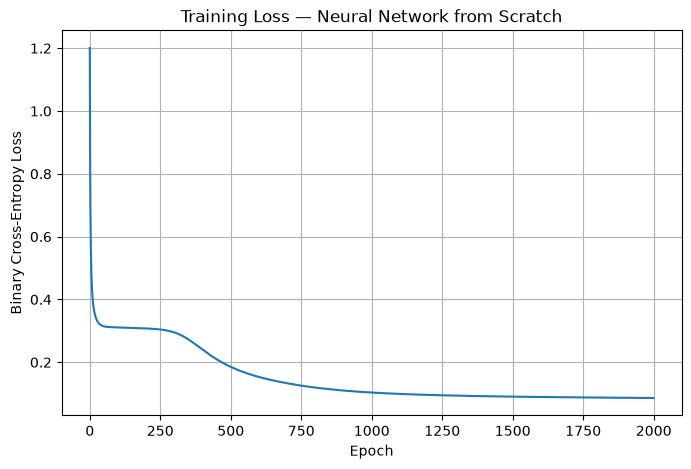

Initial loss: 1.200653
Final loss:   0.086264


In [6]:

# Training configuration
learning_rate = 0.5
epochs = 2000

loss_history = []

for epoch in range(epochs):
    # Forward propagation
    predictions, cache = forward_pass(
        X_train, W1, b1, W2, b2
    )

    # Calculate loss
    loss = binary_cross_entropy(y_train, predictions)
    loss_history.append(float(loss))

    # Backpropagation
    gradients = backward_pass(
        y_train, W1, W2, cache
    )

    # Update parameters using gradient descent
    W1 -= learning_rate * gradients["dW1"]
    b1 -= learning_rate * gradients["db1"]

    W2 -= learning_rate * gradients["dW2"]
    b2 -= learning_rate * gradients["db2"]

# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss — Neural Network from Scratch")
plt.grid(True)
plt.show()

print(f"Initial loss: {loss_history[0]:.6f}")
print(f"Final loss:   {loss_history[-1]:.6f}")


In [7]:

# Generate predictions for unseen test data
test_probabilities, _ = forward_pass(
    X_test, W1, b1, W2, b2
)

# Convert probabilities into binary class predictions
test_predictions = (test_probabilities >= 0.5).astype(int)

# Calculate test accuracy
test_accuracy = accuracy_score(
    y_test.ravel(),
    test_predictions.ravel()
)

print(f"Test Accuracy: {test_accuracy:.2%}")
print("\nClassification Report:")
print(
    classification_report(
        y_test.ravel(),
        test_predictions.ravel(),
        target_names=["Class 0", "Class 1"]
    )
)


Test Accuracy: 99.00%

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.99      0.99      0.99       100
     Class 1       0.99      0.99      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200




## Day 5 — Backpropagation from Scratch

### Objective
Implement a simple neural network using NumPy without TensorFlow or PyTorch.

### Architecture
- Input layer: 2 features
- Hidden layer: 8 neurons with tanh activation
- Output layer: 1 neuron with sigmoid activation
- Loss: Binary cross-entropy
- Optimizer: Gradient descent
- Learning rate: 0.5
- Training epochs: 2,000

### Implementation
1. Forward propagation calculates predictions.
2. Binary cross-entropy measures prediction error.
3. Backpropagation calculates gradients using the chain rule.
4. Numerical gradient checking verifies selected weight gradients.
5. Gradient descent updates weights and biases.
6. Test evaluation measures performance on unseen examples.

### Results
- Initial training loss: 1.200653
- Final training loss: 0.086264
- Test accuracy: 99.00% (198/200)
- Precision, recall, and F1-score: 0.99 for both classes.

### Important Limitation
The model was trained and evaluated on a synthetic
`make_moons` dataset. These results demonstrate the
backpropagation implementation, not the performance of
the Parakh fake-review detection model on real reviews.
